In [10]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_curve, precision_score, recall_score, classification_report, confusion_matrix

# Styling for Seaborn and Matplotlib
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [9]:
# Set random seed for reproducibility
np.random.seed(42)

# 1. Generate Video Telemetry (Every 1 second for a 1-hour exam = 3600 seconds)
time_video = np.arange(0, 3600, 1)
n_samples = len(time_video)

# Simulate eye gaze coordinates and head posture with random noise & connection drops
gaze_x = np.random.normal(50, 5, n_samples)
gaze_y = np.random.normal(50, 5, n_samples)
audio_level = np.random.exponential(2.0, n_samples)

# Introduce "Connection Dropped" Trap: Randomly inject NaN blocks (simulate bad internet)
nan_mask_1 = slice(500, 750)    # 250 seconds drop
nan_mask_2 = slice(1800, 2050)  # 250 seconds drop
gaze_x[nan_mask_1] = np.nan
gaze_y[nan_mask_1] = np.nan
audio_level[nan_mask_2] = np.nan

video_telemetry = pd.DataFrame({
    'timestamp': pd.to_datetime(time_video, unit='s', origin='2026-06-06 09:00:00'),
    'gaze_x': gaze_x,
    'gaze_y': gaze_y,
    'audio_level': audio_level
})

# 2. Generate System Events (Asynchronous - only logs when tab switches or copy/paste occur)
event_times = np.sort(np.random.choice(time_video, size=50, replace=False))
event_types = np.random.choice(['tab_switch', 'copy_paste', 'right_click'], size=50)

system_events = pd.DataFrame({
    'timestamp': pd.to_datetime(event_times, unit='s', origin='2026-06-06 09:00:00'),
    'event_type': event_types,
    'event_flag': 1
})

# Target label: Cheating behavior (e.g., sustained looking away + suspicious system events)
# Highly imbalanced: only 2% of the timeline represents actual cheating
is_cheating = np.zeros(n_samples, dtype=int)
is_cheating[1000:1040] = 1
is_cheating[2500:2530] = 1

video_telemetry['is_cheating'] = is_cheating

print(f"Video Telemetry Shape: {video_telemetry.shape}")
print(f"System Events Shape: {system_events.shape}")

Video Telemetry Shape: (3600, 5)
System Events Shape: (50, 3)


In [4]:
# Sort both dataframes by timestamp before merging asof
video_telemetry = video_telemetry.sort_values('timestamp')
system_events = system_events.sort_values('timestamp')

# Use merge_asof to align asynchronous system events to the nearest video timestamp
merged_df = pd.merge_asof(
    video_telemetry,
    system_events,
    on='timestamp',
    direction='nearest',
    tolerance=pd.Timedelta('2s')
)

# Fill missing event flags with 0 (meaning no system event occurred at that second)
merged_df['event_flag'] = merged_df['event_flag'].fillna(0)
merged_df['event_type'] = merged_df['event_type'].fillna('none')

print("Asynchronous merge completed successfully using pd.merge_asof.")
display(merged_df[['timestamp', 'gaze_x', 'event_type', 'event_flag']].head())

Asynchronous merge completed successfully using pd.merge_asof.


,timestamp,gaze_x,event_type,event_flag
0,2026-06-06 09:00:00,52.483571,none,0.0
1,2026-06-06 09:00:01,49.308678,none,0.0
2,2026-06-06 09:00:02,53.238443,none,0.0
3,2026-06-06 09:00:03,57.615149,none,0.0
4,2026-06-06 09:00:04,48.829233,none,0.0


In [5]:
# Check initial missing values
print("Missing values before cleaning:")
print(merged_df[['gaze_x', 'gaze_y', 'audio_level']].isnull().sum())

# Mathematically handle missing sensor data using interpolation and forward-filling
# Linear interpolation bridges gaps gracefully without throwing away the timeline
merged_df['gaze_x'] = merged_df['gaze_x'].interpolate(method='linear').ffill().bfill()
merged_df['gaze_y'] = merged_df['gaze_y'].interpolate(method='linear').ffill().bfill()
merged_df['audio_level'] = merged_df['audio_level'].interpolate(method='linear').ffill().bfill()

print("\nMissing values after cleaning:")
print(merged_df[['gaze_x', 'gaze_y', 'audio_level']].isnull().sum())

Missing values before cleaning:
gaze_x         250
gaze_y         250
audio_level    250
dtype: int64

Missing values after cleaning:
gaze_x         0
gaze_y         0
audio_level    0
dtype: int64


In [6]:
# Engineer Rolling Averages (e.g., 10-second rolling window) 
# to smooth out brief sneezes, stretches, or momentary glances.
window_size = 10

merged_df['gaze_x_roll_mean'] = merged_df['gaze_x'].rolling(window=window_size, min_periods=1).mean()
merged_df['gaze_y_roll_mean'] = merged_df['gaze_y'].rolling(window=window_size, min_periods=1).mean()
merged_df['audio_roll_mean'] = merged_df['audio_level'].rolling(window=window_size, min_periods=1).mean()

# Rolling standard deviation to capture erratic sustained movements
merged_df['gaze_x_roll_std'] = merged_df['gaze_x'].rolling(window=window_size, min_periods=1).std().fillna(0)
merged_df['audio_roll_std'] = merged_df['audio_level'].rolling(window=window_size, min_periods=1).std().fillna(0)

# Convert categorical event types into dummy/indicator variables
merged_df = pd.get_dummies(merged_df, columns=['event_type'], drop_first=True)

print("Feature engineering with rolling windows complete.")

Feature engineering with rolling windows complete.


In [7]:
# Define features and target
feature_cols = [
    'gaze_x_roll_mean', 'gaze_y_roll_mean', 'audio_roll_mean',
    'gaze_x_roll_std', 'audio_roll_std', 'event_flag'
]

# Add dummy columns created by pd.get_dummies if present
dummy_cols = [col for col in merged_df.columns if col.startswith('event_type_')]
feature_cols.extend(dummy_cols)

X = merged_df[feature_cols]
y = merged_df['is_cheating']

# Train-test split (chronological or random stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Train a robust classifier with class_weight='balanced' to tackle heavy class imbalance
model = RandomForestClassifier(
    n_estimators=100, 
    class_weight='balanced', 
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)

# Get probabilities instead of hard predictions
y_probs = model.predict_proba(X_test)[:, 1]

print("Model trained successfully with class weighting.")

Model trained successfully with class weighting.


Calculated Optimal Decision Threshold for 90%+ Precision: 0.7700

--- Classification Report at Custom Threshold ---
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1059
           1       1.00      0.05      0.09        21

    accuracy                           0.98      1080
   macro avg       0.99      0.52      0.54      1080
weighted avg       0.98      0.98      0.97      1080



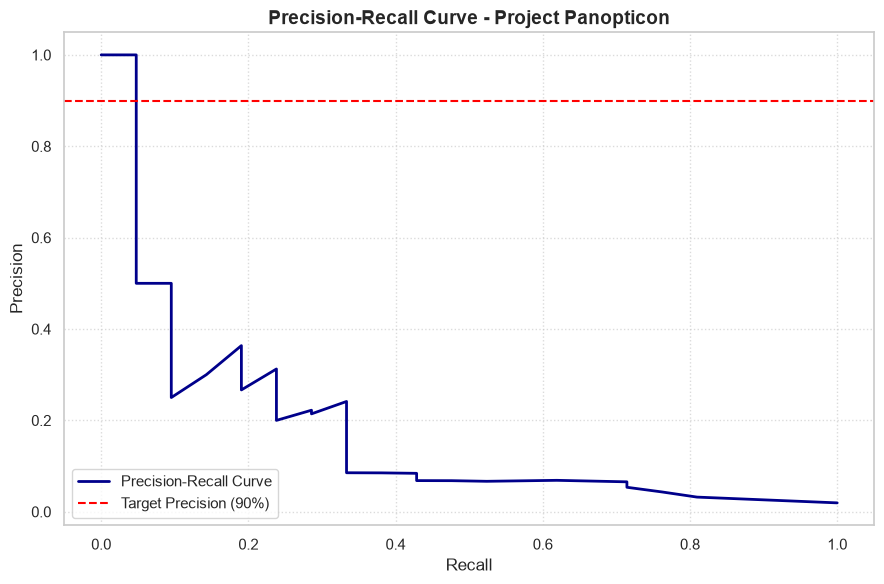

In [8]:
# Calculate Precision-Recall curve
precisions, recalls, thresholds = precision_recall_curve(y_test, y_probs)

# Find the optimal threshold that guarantees at least 90% Precision (minimize false accusations)
target_precision = 0.90
valid_indices = np.where(precisions >= target_precision)[0]

if len(valid_indices) > 0:
    # Choose the threshold that maximizes recall while keeping precision >= 90%
    best_index = valid_indices[0]
    optimal_threshold = thresholds[best_index] if best_index < len(thresholds) else 0.9
else:
    optimal_threshold = 0.90  # Default fallback safeguard

print(f"Calculated Optimal Decision Threshold for 90%+ Precision: {optimal_threshold:.4f}")

# Apply custom decision threshold
y_pred_custom = (y_probs >= optimal_threshold).astype(int)

# Evaluation Metrics
print("\n--- Classification Report at Custom Threshold ---")
print(classification_report(y_test, y_pred_custom, zero_division=0))

# Plot Precision-Recall Curve with Seaborn / Matplotlib
plt.figure(figsize=(9, 6))
plt.plot(recalls, precisions, label='Precision-Recall Curve', color='darkblue', lw=2)
plt.axhline(y=0.90, color='red', linestyle='--', label='Target Precision (90%)')
plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Precision-Recall Curve - Project Panopticon', fontsize=14, fontweight='bold')
plt.legend(loc='lower left', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()